Laatst bijgewerkt: 15-5-2026 RZ

# Hypothese

> Starbucks(y) <- Koffie(x1), Suiker(x2)

> H0: De prijs van koffie (KC=F) heeft geen significante invloed op de prijs van het aandeel Starbucks (SBUX).

> H1: De prijs van koffie (KC=F) heeft wel een significante invloed op de prijs van het aandeel Starbucks (SBUX).

> In eerste instantie is Suiker buiten beschouwing gelaten.

# Initialisatie

In [1]:
# @title Inlezen libraries
# last updated: 2024-12-12
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import datetime as dt
import yfinance as yf
import seaborn as sns
from scipy import stats
from statsmodels.tsa.stattools import grangercausalitytests

#Clear output
from google.colab import output
output.clear()

In [2]:
# @title Inlezen data
# koffie > starbucks

#Start en eind datum voor het inzlezen van de data
start = dt.datetime(2024,2,1)
end = dt.datetime(2024,12,1)

koffie = yf.download('KC=F', start, end).tz_localize(None)
starbucks = yf.download('SBUX', start, end).tz_localize(None)

print("\n\n",koffie.head(1),"\n")
print(starbucks.head(1))

/tmp/ipykernel_1108/3744469522.py:8: FutureWarning: YF.download() has changed argument auto_adjust default to True
  koffie = yf.download('KC=F', start, end).tz_localize(None)
[*********************100%***********************]  1 of 1 completed
/tmp/ipykernel_1108/3744469522.py:9: FutureWarning: YF.download() has changed argument auto_adjust default to True
  starbucks = yf.download('SBUX', start, end).tz_localize(None)
[*********************100%***********************]  1 of 1 completed



 Price            Close        High         Low        Open Volume
Ticker            KC=F        KC=F        KC=F        KC=F   KC=F
Date                                                             
2024-02-01  194.199997  195.300003  191.149994  193.399994  25789 

Price           Close       High        Low       Open    Volume
Ticker           SBUX       SBUX       SBUX       SBUX      SBUX
Date                                                            
2024-02-01  88.075142  88.292095  86.660204  87.820449  15001500


In [3]:
# @title Filter (Adj Close)
koffie_adj_close = koffie.loc[:, ["Close"]]
starbucks_adj_close = starbucks.loc[:, ["Close"]]

print(koffie_adj_close.head(3),"\n")
print(starbucks_adj_close.head(3))

Price            Close
Ticker            KC=F
Date                  
2024-02-01  194.199997
2024-02-02  191.949997
2024-02-05  189.500000 

Price           Close
Ticker           SBUX
Date                 
2024-02-01  88.075142
2024-02-02  87.716667
2024-02-05  87.263908


# Define Functions

In [4]:
# @title Plot demo
def plot_series_demo():

  # let op: verticaal lijntje staat nu nog hard gecodeerd!
  # m.a.w. als we "boven" de tijdsreeks aanpassen dan beweegt het lijntje
  # niet mee en kan buiten het tijdsvak vallen. Voor het voorbeeld is een
  # tijdvak gebruikt 2024-2-1 tot 2024-12-1

  # tbv demo eventueel (fixed time range)

  # legends and annotations
  local_max = pd.to_datetime('2024-2-1')
  offset = pd.Timedelta(30, 'D')

  ax[0].legend(['input'], loc=2)
  ax[0].get_xticklabels()[2].set(weight='heavy', color='red')
  ax[0].axvline(local_max, alpha=0.3, color='red')

  ax[1].legend(['shift(30)'], loc=2)
  ax[1].get_xticklabels()[2].set(weight='heavy', color='red')
  ax[1].axvline(local_max + offset, alpha=0.3, color='red')

  return


In [5]:
# @title Correlation

# van chi square naar r

def chisquare2correlation(x, y):
    """
    Demonstrate relationship between chi-square and correlation

    Parameters:
    x, y: arrays of continuous data
    """
    # Calculate Pearson correlation
    r, p_value = stats.pearsonr(x, y)

    # Calculate chi-square from correlation
    n = len(x)
    chi_square_from_r = n * (r ** 2)

    print(f"Sample size (n): {n}")
    print(f"Correlation coefficient (r): {r:.4f}")
    print(f"Chi-square calculated from r: {chi_square_from_r:.4f}")


In [6]:
# @title Granger

def test_granger_causality(df, maxlag=10):
    """
    Test Granger causality between two time series

    Parameters:
    df: pandas Dataframe with datetime index
    maxlag: int, maximum number of lags to test

    Returns:
    Dictionary containing test results
    """
    # Perform Granger causality tests in both directions
    print("Testing if Coffee Futures (KCF) Granger-causes Starbucks (SBUX):\n")
    gc_result1 = grangercausalitytests(df[['SBUX', 'KCF']], maxlag=maxlag, verbose=False)

    # Extract and format results
    results = {
        'KC=F_causes_SBUX': {lag: gc_result1[lag][0]['ssr_chi2test'][1] for lag in range(1, maxlag + 1)},
    }

    return results

# Use of shift()

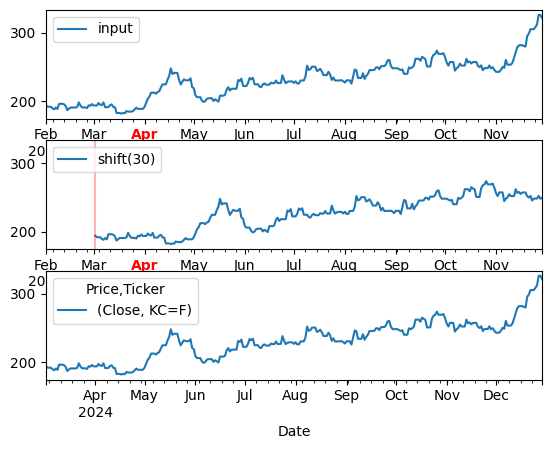

In [7]:
fig, ax = plt.subplots(3, sharey=True)

# apply a frequency to the data
koffie = koffie_adj_close.asfreq('D', method='pad')

koffie.plot(ax=ax[0])
koffie.shift(30).plot(ax=ax[1])
koffie.shift(periods=30, freq='D').plot(ax=ax[2])

plot_series_demo()

# Plot time series (KC=F, SBUX, Combined)

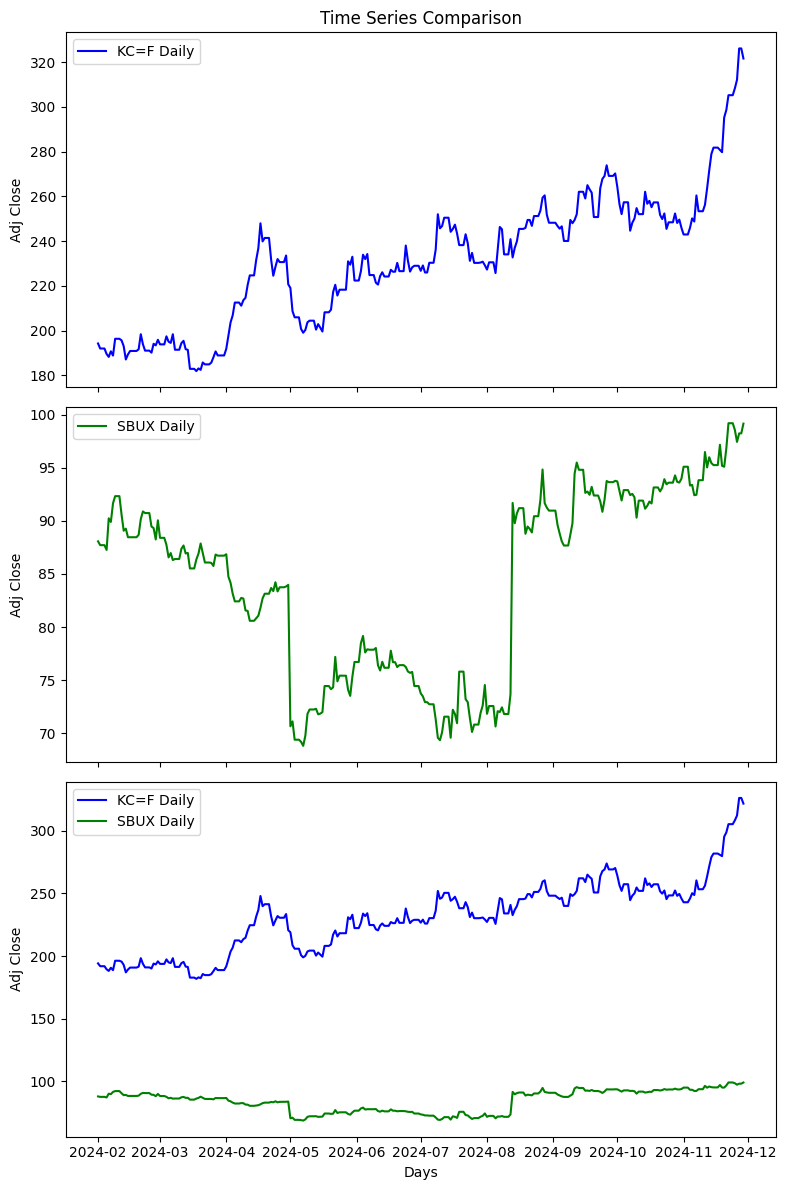

In [8]:
# @title Combine (concat)
koffie_daily = koffie_adj_close.asfreq('D', method='pad')
starbucks_daily = starbucks_adj_close.asfreq('D', method='pad')

fig, axes = plt.subplots(3, 1, figsize=(8, 12), sharex=True)

axes[0].plot(koffie_daily, label='KC=F Daily', color='blue')
axes[0].set_title('Time Series Comparison')
axes[0].set_ylabel('Adj Close')
axes[0].legend()

axes[1].plot(starbucks_daily, label='SBUX Daily', color='green')
axes[1].set_ylabel('Adj Close')
axes[1].legend()

axes[2].plot(koffie_daily, label='KC=F Daily', color='blue')
axes[2].plot(starbucks_daily, label='SBUX Daily', color='green')
axes[2].set_ylabel('Adj Close')
axes[2].legend()

# Final adjustments
plt.xlabel('Days')
plt.tight_layout()
plt.show()

# Linear Regression

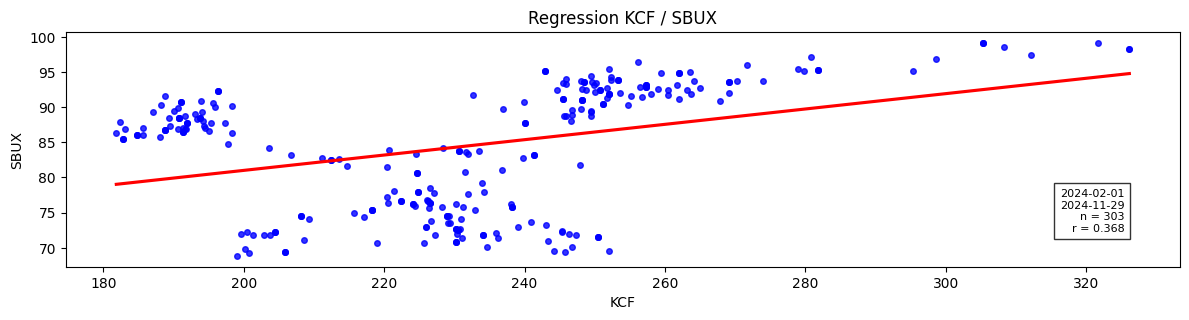

In [9]:
# @title plot cross correlation without lag

# Samenvoegen middels concat
portfolio = pd.concat([starbucks_daily, koffie_daily], axis=1)
portfolio.columns = ['SBUX', 'KCF']
portfolio.head(2)

# Prepare plot
fig, ax = plt.subplots(1, 1, figsize=(12, 5))

# Date range, n, correlation coefficient, p-value
start_date = portfolio.index[0].strftime('%Y-%m-%d')
end_date = portfolio.index[-1].strftime('%Y-%m-%d')
n = len(portfolio)
correlation = stats.pearsonr(portfolio['KCF'], portfolio['SBUX'])[0]
pvalue = stats.pearsonr(portfolio['KCF'], portfolio['SBUX'])[1]

# Create regression plot
sns.regplot(x='KCF', y='SBUX', data=portfolio, ci=None, ax=ax,
            scatter_kws={'s': 16, 'alpha': .8, 'color': 'blue'},
            line_kws={'color': 'red'})
ax.set_aspect('equal')
ax.set_title('Regression KCF / SBUX')
ax.text(0.95, 0.15, f'{start_date}\n{end_date}\nn = {n}\nr = {correlation:.3f}',
        transform=ax.transAxes,
        bbox=dict(facecolor='white', alpha=0.8),
        horizontalalignment='right',
        fontsize=8)

plt.tight_layout()

In [10]:
# @title create lag columns using shift

def make_lags(timeseries, lags):
    return pd.concat(
        {
            f'KCF-{i}': timeseries.shift(-i)
            for i in range(1, lags + 1)
        },
        axis=1)


Xlag = make_lags(portfolio['KCF'], lags=6)
df = pd.concat([portfolio,Xlag], axis=1)
df.head(3)

,SBUX,KCF,KCF-1,KCF-2,KCF-3,KCF-4,KCF-5,KCF-6
Date,,,,,,,,
2024-02-01,88.075142,194.199997,191.949997,191.949997,191.949997,189.500000,188.199997,190.699997
2024-02-02,87.716667,191.949997,191.949997,191.949997,189.500000,188.199997,190.699997,188.800003
2024-02-03,87.716667,191.949997,191.949997,189.500000,188.199997,190.699997,188.800003,196.300003


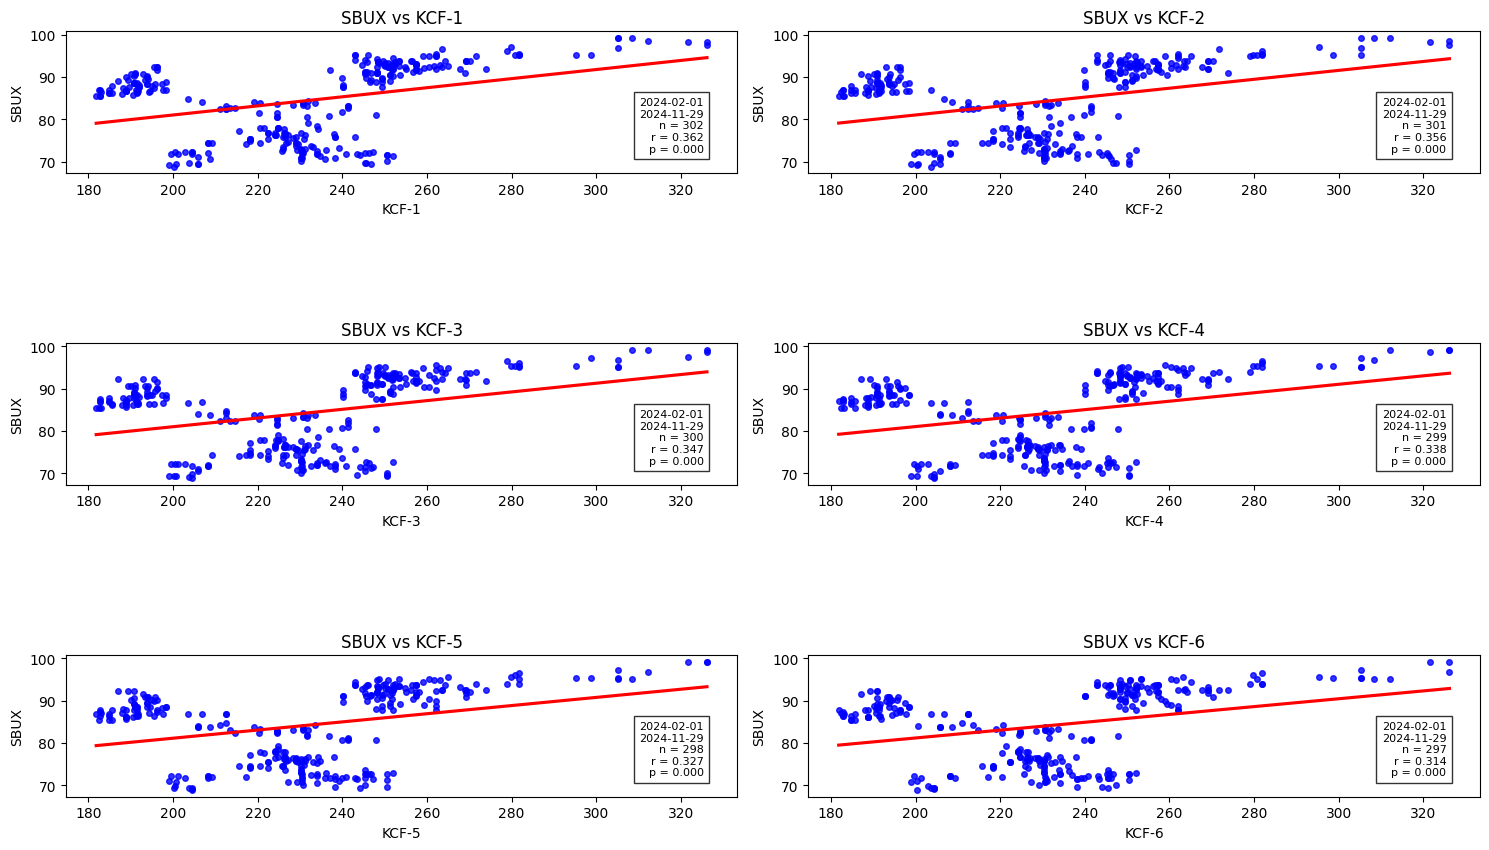

In [11]:
# @title plot cross correlation with lag

comparison_cols = [col for col in df.columns if col != 'SBUX' and col != 'KCF' and col != 'Date']

# Calculate number of rows needed for subplot grid
n_plots = len(comparison_cols)
n_rows = (n_plots + 1) // 2  # Two plots per row, rounded up
n_cols = 2

# Create figure
fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 10))
axes = axes.flatten()  # Flatten to make indexing easier

# For each comparison column
for idx, col in enumerate(comparison_cols):
    # Calculate statistics
    valid_mask = ~(df['SBUX'].isna() | df[col].isna())  # Remove NaN values
    correlation, p_value = stats.pearsonr(df['SBUX'][valid_mask], df[col][valid_mask])
    n = valid_mask.sum()
    start_date = df.index[0].strftime('%Y-%m-%d')
    end_date = df.index[-1].strftime('%Y-%m-%d')

    # Create scatter plot with regression line
    sns.regplot(data=df, x=col, y='SBUX',
                scatter_kws={'s': 16, 'alpha': .8, 'color': 'blue'},
                line_kws={'color': 'red'},
                ci=None,
                ax=axes[idx])

    # Add text box with statistics
    axes[idx].text(0.95, 0.15,
                  f'{start_date}\n{end_date}\nn = {n}\nr = {correlation:.3f}\np = {p_value:.3f}',
                  transform=axes[idx].transAxes,
                  bbox=dict(facecolor='white', alpha=0.8),
                  horizontalalignment='right',
                  fontsize=8)

    # Set title
    axes[idx].set_title(f'SBUX vs {col}')
    axes[idx].set_aspect('equal')

# Remove any empty subplots
for idx in range(len(comparison_cols), len(axes)):
    fig.delaxes(axes[idx])

plt.tight_layout()
plt.show()

Hierboven hebben we per shift (1,2,3,...) een correlatie coefficient laten berekenen. In dit voorbeeld is de hoogste correlatie coëfficient 0.368 (SBUX-KCF). Onderdeel van de statmodels bibliotheek is een specifieke (Cross Correlation) grafiek.

<Figure size 1000x500 with 0 Axes>

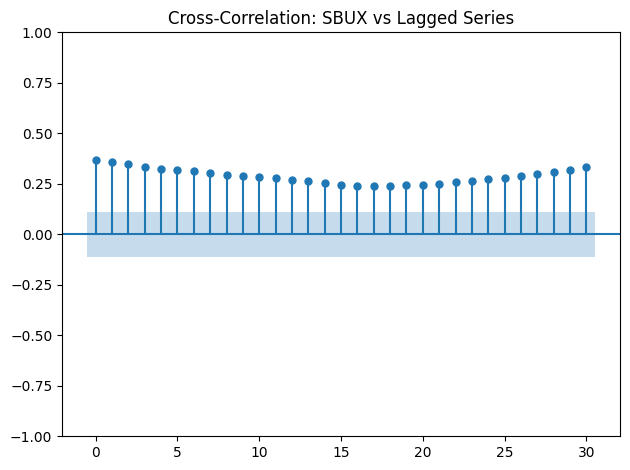

In [12]:
# @title lag-plot (or correlogram)
from statsmodels.graphics.tsaplots import plot_ccf

# Create the plot
plt.figure(figsize=(10, 5))

# Plot CCF (Cross-Correlation Function)
plot_ccf(df['SBUX'],
         df['KCF'],  # or any other lagged series you want to compare with
         alpha=0.05,           # 95% confidence interval
         lags=30,              # number of lags to show
         title='Cross-Correlation: SBUX vs Lagged Series')

plt.tight_layout()
plt.show()

De interpretatie van de grafiek is als volgt:

Deze grafiek toont de cross-correlatie tussen SBUX (Starbucks aandeel) en een lagged versie van de Koffie (KCF) tijdsreeks.



* De x-as toont de lags (vertragingen) van 0 tot 30
* De y-as toont de correlatiecoëfficiënten, die kunnen variëren van -1 tot +1
* De blauwe stippen verbonden met verticale lijnen tonen de correlatie voor elke lag
* Het lichtblauwe gebied rondom 0 vertegenwoordigt het 95% betrouwbaarheidsinterval

Wat we kunnen zien:

* Bij lag 0 is er een correlatie van ongeveer 0.35
* De correlaties blijven redelijk consistent positief rond de 0.25-0.35
* Alle correlaties zijn statistisch significant omdat ze buiten het blauwe betrouwbaarheidsinterval vallen
* Er is geen duidelijke afname van correlatie naarmate de lag toeneemt

Deze persistente positieve correlatie over verschillende lags suggereert dat:

* Er een sterke mate van persistentie is in de relatie tussen de twee reeksen
* Historische waarden blijven voorspellende waarde houden, zelfs na 30 perioden
* Er mogelijk sprake is van een structureel verband tussen de twee reeksen

Dit patroon zou kunnen wijzen op een sterke onderlinge afhankelijkheid tussen de twee tijdreeksen of op gemeenschappelijke onderliggende factoren die beide reeksen beïnvloeden.


**Bron: claude.ai**

Tenslotte, voor de liefhebbers is er de Granger Causality test. Deze test is specifiek bedoeld om de relatie tussen 2 tijdreeksen te toetsen met behulp van de zgn. chi-kwadraat test.

"The Granger causality test is a statistical hypothesis test for determining whether one time series is useful in forecasting another, first proposed in 1969. Ordinarily, regressions reflect "mere" correlations, but Clive Granger argued that causality in economics could be tested for by measuring the ability to predict the future values of a time series using prior values of another time series." (bron: wikipedia)

Een voorbeeld van een uitwerking van de Granger Causality test zou een toekomstige verbetering van dit notebook kunnen zijn.